# Đánh giá và so sánh ConvNeXt-Tiny vs ResNet18 trên CIFAR-10

**Mục tiêu:** Đánh giá hai checkpoint đã huấn luyện trên test set CIFAR-10, đo chi phí tính toán, tạo hình trực quan và tổng hợp bảng so sánh phục vụ báo cáo.

**Nguyên tắc:**
- Notebook chỉ **đọc artifacts đã lưu**, không chạy lại training.
- Test set chỉ dùng **một lần** để đánh giá cuối — không dùng để chọn epoch/hyperparameter.
- Mọi kết quả đều ghi rõ device, batch size, input size và nguồn FLOPs.

**Yêu cầu trước khi chạy:**
- Đã huấn luyện xong, có `best.pt` cho cả hai model trong `artifacts/checkpoints/<run_name>/`.
- Có sẵn `configs/default.json` và dữ liệu CIFAR-10 tại `data/raw`.
- Đã cài: `torch`, `torchvision`, `scikit-learn`, `matplotlib`, `pandas`, `numpy`.

 Thiết lập môi trường

Import các module trong package `src.cifar_compare` và thêm project root vào `sys.path`.
Nếu bạn chạy notebook từ thư mục khác, hãy sửa `PROJECT_ROOT` cho đúng.

In [2]:
import json
import os
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Tìm project root từ thư mục hiện tại hoặc các thư mục cha.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in candidates
     if (path / "src/cifar_compare/evaluate.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Không tìm thấy project root (cần có src/cifar_compare/evaluate.py). "
        "Hãy chạy notebook bên trong project."
    )
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.cifar_compare.evaluate import evaluate_checkpoint
from src.cifar_compare.profiling import profile_model
from src.cifar_compare.visualize import visualize_all
from src.cifar_compare.utils import load_config

print(f"Project root: {PROJECT_ROOT}")
print(f"Python: {sys.version.split()[0]}")
import torch, torchvision
print(f"torch: {torch.__version__} | torchvision: {torchvision.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Project root: d:\Môn năm 3\ConvNeXt_ResNet18_tren_CIFAR-10\ConvNeXtiny_vs_ResNet18_A_Comparative_Study_on_CIFAR10_Classification
Python: 3.12.10
torch: 2.11.0+cu128 | torchvision: 0.26.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU


1. Cấu hình đường dẫn và checkpoint

Đọc config mặc định, sau đó chỉ định **tên thư mục run** cho từng model.
Sửa `RUNS` cho khớp với thư mục checkpoint thực tế của bạn
(mặc định `train.py` đặt tên run theo `model_YYYYMMDD_HHMMSS` nếu không truyền `--run-name`).

In [3]:
DEFAULTS = {
    "data_root": "data/raw",
    "split_path": "data/splits/split_indices.json",
    "seed": 42,
    "val_size": 5000,
    "input_size": 224,
    "batch_size": 32,
    "num_workers": 4,
    "output_dir": "artifacts",
    "device": "auto",
    "eval_batch_size": 64,
    "warmup": 20,
    "repeats": 100,
}
config_path = PROJECT_ROOT / "configs/default.json"
config = load_config(config_path, DEFAULTS)

# !!! QUAN TRỌNG: chỉnh RUNS cho khớp thư mục checkpoint thực tế !!!
RUNS = {
    "resnet18": "resnet18_20261112_213427",           # ví dụ: "resnet18_20250101_120000"
    "convnext_tiny": "convnext_tiny_20261112_220838", # ví dụ: "convnext_tiny_20250101_130000"
}

CHECKPOINT_PATHS = {
    model: Path(config["output_dir"]) / "checkpoints" / run / "best.pt"
    for model, run in RUNS.items()
}

print("Kiểm tra checkpoint:")
for model, path in CHECKPOINT_PATHS.items():
    status = "✓" if path.exists() else "✗"
    print(f"  {status} {model}: {path}")
    if not path.exists():
        raise FileNotFoundError(
            f"Không tìm thấy checkpoint cho {model} tại {path}. "
            f"Hãy kiểm tra lại RUNS hoặc đường dẫn."
        )

Kiểm tra checkpoint:
  ✓ resnet18: artifacts\checkpoints\resnet18_20261112_213427\best.pt
  ✓ convnext_tiny: artifacts\checkpoints\convnext_tiny_20261112_220838\best.pt


Đánh giá trên test set (accuracy, macro-F1, per-class)
Gọi `evaluate_checkpoint` cho từng model. Hàm này:
- Load checkpoint ở `best.pt` (validation-best, không phải test-best).
- Chạy eval trên toàn bộ 10.000 ảnh test CIFAR-10 với transform eval (không augmentation).
- Lưu `test_metrics.json`, `test_predictions.npz`, `confusion_matrix.npy` vào `artifacts/logs/<run_name>/` và `artifacts/predictions/<run_name>/`.
Kết quả trả về là dict metrics đầy đủ, ta sẽ dùng cho các bảng tổng hợp sau.

In [4]:
test_metrics = {}

for model, ckpt_path in CHECKPOINT_PATHS.items():
    print(f"\n{'='*70}")
    print(f"Đang đánh giá: {model}")
    print(f"{'='*70}")
    metrics = evaluate_checkpoint(
        checkpoint_path=ckpt_path,
        config=config,
        output_dir=config["output_dir"],
        device=None,  # tự động chọn theo config["device"]
    )
    test_metrics[model] = metrics

print("\n✓ Đánh giá hoàn tất cho cả hai model.")


Đang đánh giá: resnet18
[evaluate] Checkpoint: artifacts\checkpoints\resnet18_20261112_213427\best.pt
[evaluate] Split: CIFAR-10 official test (10.000 mẫu)
[evaluate] Device: cuda | input_size: 224 | batch: 32
[evaluate] Accuracy=0.9644 | Macro-F1=0.9643 | Loss=0.1337
[evaluate] Đã lưu: artifacts\logs\resnet18_20261112_213427\test_metrics.json
[evaluate] Đã lưu: artifacts\predictions\resnet18_20261112_213427\test_predictions.npz

Đang đánh giá: convnext_tiny
[evaluate] Checkpoint: artifacts\checkpoints\convnext_tiny_20261112_220838\best.pt
[evaluate] Split: CIFAR-10 official test (10.000 mẫu)
[evaluate] Device: cuda | input_size: 224 | batch: 32
[evaluate] Accuracy=0.9824 | Macro-F1=0.9824 | Loss=0.0716
[evaluate] Đã lưu: artifacts\logs\convnext_tiny_20261112_220838\test_metrics.json
[evaluate] Đã lưu: artifacts\predictions\convnext_tiny_20261112_220838\test_predictions.npz

✓ Đánh giá hoàn tất cho cả hai model.


3. Đo chi phí tính toán

Gọi `profile_model` cho từng kiến trúc. Hàm này đo:
- **Parameters**: đếm trực tiếp trên model đã thay head 10 lớp.
- **FLOPs/MACs**: giá trị tham chiếu từ torchvision (input 224×224, batch=1, FP32).
- **Latency**: đo trung bình sau warm-up, dùng `cuda.Event` (CUDA) hoặc `time.perf_counter` (CPU).
- **Throughput**: samples/giây tính từ latency trung bình.
- **Peak memory**: `max_memory_allocated` (chỉ có trên CUDA).

Lưu ý: latency chỉ tính forward pass, **không gồm** data loading hay khởi tạo model.

In [5]:
profile_results = {}

for model in ["resnet18", "convnext_tiny"]:
    print(f"\n{'='*70}")
    print(f"Đang profiling: {model}")
    print(f"{'='*70}")
    result = profile_model(model, config, device=None)
    profile_results[model] = result

print("\n✓ Profiling hoàn tất cho cả hai model.")


Đang profiling: resnet18
[profiling] GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
[profiling] VRAM: 12.8 GB | sm_120
[profiling] resnet18: Latency mean=19.77ms p95=29.94ms | Throughput=1619.0 samples/s | Peak Mem=285MB
[profiling] Đã lưu: artifacts\profiling\resnet18_profile.json

Đang profiling: convnext_tiny
[profiling] GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU
[profiling] VRAM: 12.8 GB | sm_120
[profiling] convnext_tiny: Latency mean=106.06ms p95=110.83ms | Throughput=301.7 samples/s | Peak Mem=503MB
[profiling] Đã lưu: artifacts\profiling\convnext_tiny_profile.json

✓ Profiling hoàn tất cho cả hai model.


4. Vẽ learning curves, confusion matrix và ảnh phân loại sai

`visualize_all` đọc artifacts đã lưu và tạo:
- `learning_curves.png`: train/val loss & accuracy theo epoch, đánh dấu best epoch.
- `confusion_matrix.png` và `confusion_matrix_normalized.png`.
- `misclassified.png`: 16 ảnh sai có confidence cao nhất.
- `per_class_f1.png`: F1 từng lớp.
- `manifest.json`: liệt kê các hình đã tạo.

Tất cả hình lưu vào `artifacts/figures/<run_name>/`.

In [6]:
for model, run_name in RUNS.items():
    print(f"\n{'='*70}")
    print(f"Đang tạo hình cho: {run_name}")
    print(f"{'='*70}")
    visualize_all(run_name, config)

print("\n✓ Đã tạo xong toàn bộ hình.")


Đang tạo hình cho: resnet18_20261112_213427
[visualize] Learning curves -> artifacts\figures\resnet18_20261112_213427\learning_curves.png
[visualize] Confusion matrix (count) -> artifacts\figures\resnet18_20261112_213427\confusion_matrix.png
[visualize] Confusion matrix (norm) -> artifacts\figures\resnet18_20261112_213427\confusion_matrix_normalized.png
[visualize] Misclassified -> artifacts\figures\resnet18_20261112_213427\misclassified.png
[visualize] Per-class F1 -> artifacts\figures\resnet18_20261112_213427\per_class_f1.png
[visualize] Manifest -> artifacts\figures\resnet18_20261112_213427\manifest.json

Đang tạo hình cho: convnext_tiny_20261112_220838
[visualize] Learning curves -> artifacts\figures\convnext_tiny_20261112_220838\learning_curves.png
[visualize] Confusion matrix (count) -> artifacts\figures\convnext_tiny_20261112_220838\confusion_matrix.png
[visualize] Confusion matrix (norm) -> artifacts\figures\convnext_tiny_20261112_220838\confusion_matrix_normalized.png
[visual

5. Bảng tổng hợp

5.1. Bảng accuracy, macro-F1 và F1 từng lớp trên test

In [7]:
def build_test_table(metrics_dict):
    rows = []
    for model, m in metrics_dict.items():
        per_class = m["per_class"]
        class_names = [
            c for c in per_class
            if c not in ("accuracy", "macro avg", "weighted avg")
        ]
        row = {
            "Model": model,
            "Test Accuracy": m["accuracy"],
            "Macro-F1": m["macro_f1"],
            "Test Loss": m["loss"],
        }
        for c in class_names:
            row[f"F1_{c}"] = per_class[c]["f1-score"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model").round(4)

df_test = build_test_table(test_metrics)
print("BẢNG 1: KẾT QUẢ TRÊN TEST SET CIFAR-10 (10.000 mẫu)")
display(df_test)

BẢNG 1: KẾT QUẢ TRÊN TEST SET CIFAR-10 (10.000 mẫu)


,Test Accuracy,Macro-F1,Test Loss,F1_airplane,F1_automobile,F1_bird,F1_cat,F1_deer,F1_dog,F1_frog,F1_horse,F1_ship,F1_truck
Model,,,,,,,,,,,,,
resnet18,0.9644,0.9643,0.1337,0.9700,0.9790,0.9635,0.9167,0.9689,0.9332,0.9791,0.9809,0.9776,0.9745
convnext_tiny,0.9824,0.9824,0.0716,0.9891,0.9865,0.9844,0.9582,0.9821,0.9648,0.9940,0.9875,0.9925,0.9845


5.2. Bảng chi tiết per-class precision/recall/F1 từng model


In [8]:
for model, m in test_metrics.items():
    print(f"\n--- {model} — per-class metrics ---")
    per_class_df = pd.DataFrame(m["per_class"]).T
    display(per_class_df.round(3))


--- resnet18 — per-class metrics ---


,precision,recall,f1-score,support
airplane,0.969,0.971,0.970,1000.000
automobile,0.978,0.980,0.979,1000.000
bird,0.978,0.949,0.963,1000.000
cat,0.926,0.908,0.917,1000.000
deer,0.958,0.980,0.969,1000.000
dog,0.930,0.936,0.933,1000.000
frog,0.973,0.985,0.979,1000.000
horse,0.984,0.978,0.981,1000.000
ship,0.973,0.982,0.978,1000.000
truck,0.974,0.975,0.975,1000.000



--- convnext_tiny — per-class metrics ---


,precision,recall,f1-score,support
airplane,0.983,0.995,0.989,1000.000
automobile,0.984,0.989,0.987,1000.000
bird,0.990,0.979,0.984,1000.000
cat,0.965,0.952,0.958,1000.000
deer,0.974,0.990,0.982,1000.000
dog,0.970,0.960,0.965,1000.000
frog,0.994,0.994,0.994,1000.000
horse,0.984,0.991,0.988,1000.000
ship,0.993,0.992,0.992,1000.000
truck,0.987,0.982,0.984,1000.000


Bảng chi phí tính toán: parameters, FLOPs, tốc độ, bộ nhớ

In [9]:
def build_profiling_table(prof_dict):
    rows = []
    for model, p in prof_dict.items():
        lat = p["latency"]
        row = {
            "Model": model,
            "Params (M)": p["params_m"],
            "Params thực tế": p["params_total_actual"],
            "FLOPs (G)": p["flops_gflops"],
            "Latency mean (ms)": lat["mean_ms"],
            "Latency p95 (ms)": lat["p95_ms"],
            "Throughput (samples/s)": p["throughput_samples_per_sec"],
            "Peak memory (MB)": p["peak_memory_mb"],
            "Device": p["device"],
            "Batch size": p["batch_size"],
            "Input size": p["input_size"],
        }
        rows.append(row)
    return pd.DataFrame(rows).set_index("Model").round(3)

df_profile = build_profiling_table(profile_results)
print("BẢNG 2: CHI PHÍ TÍNH TOÁN (forward pass, không gồm data loading)")
display(df_profile)

print("\nGhi chú FLOPs:")
for model, p in profile_results.items():
    print(f"- {model}: {p['flops_definition']['source']}")
    print(f"  {p['flops_definition']['definition']}")

BẢNG 2: CHI PHÍ TÍNH TOÁN (forward pass, không gồm data loading)


,Params (M),Params thực tế,FLOPs (G),Latency mean (ms),Latency p95 (ms),Throughput (samples/s),Peak memory (MB),Device,Batch size,Input size
Model,,,,,,,,,,
resnet18,11.7,11181642,1.81,19.765,29.940,1619.000,284.618,cuda,32,224
convnext_tiny,28.6,27827818,4.46,106.061,110.829,301.714,503.163,cuda,32,224



Ghi chú FLOPs:
- resnet18: torchvision classification_table (ImageNet-1K)
  GFLOPs = 10^9 FLOPs. Giá trị tham chiếu từ torchvision, không đo trực tiếp trên model đã thay head 10 lớp.
- convnext_tiny: torchvision classification_table (ImageNet-1K)
  GFLOPs = 10^9 FLOPs. Giá trị tham chiếu từ torchvision, không đo trực tiếp trên model đã thay head 10 lớp.


5.4. Bảng tổng hợp cuối cùng (kết hợp hiệu năng và chi phí)

Bảng này là đầu ra chính cho báo cáo. Nó kết hợp:
- Accuracy, macro-F1, test loss (từ đánh giá test).
- Parameters, FLOPs, latency, throughput, peak memory (từ profiling).

In [10]:
df_final = df_test[["Test Accuracy", "Macro-F1", "Test Loss"]].join(
    df_profile[["Params (M)", "FLOPs (G)", "Latency mean (ms)",
                "Throughput (samples/s)", "Peak memory (MB)"]]
)
print("BẢNG TỔNG HỢP: HIỆU NĂNG vs CHI PHÍ TÍNH TOÁN")
display(df_final.round(4))

out_csv = Path(config["output_dir"]) / "comparison_table.csv"
df_final.to_csv(out_csv)
print(f"\n✓ Đã lưu bảng tổng hợp -> {out_csv}")

BẢNG TỔNG HỢP: HIỆU NĂNG vs CHI PHÍ TÍNH TOÁN


,Test Accuracy,Macro-F1,Test Loss,Params (M),FLOPs (G),Latency mean (ms),Throughput (samples/s),Peak memory (MB)
Model,,,,,,,,
resnet18,0.9644,0.9643,0.1337,11.7,1.81,19.765,1619.000,284.618
convnext_tiny,0.9824,0.9824,0.0716,28.6,4.46,106.061,301.714,503.163



✓ Đã lưu bảng tổng hợp -> artifacts\comparison_table.csv


6. Hiển thị hình trong notebook

Đọc các file PNG đã lưu và hiển thị trực tiếp để tiện theo dõi trong notebook.
(Hình vẫn được lưu bền vững trong `artifacts/figures/` để dùng cho báo cáo.)


Hình của: resnet18_20261112_213427

learning_curves.png:


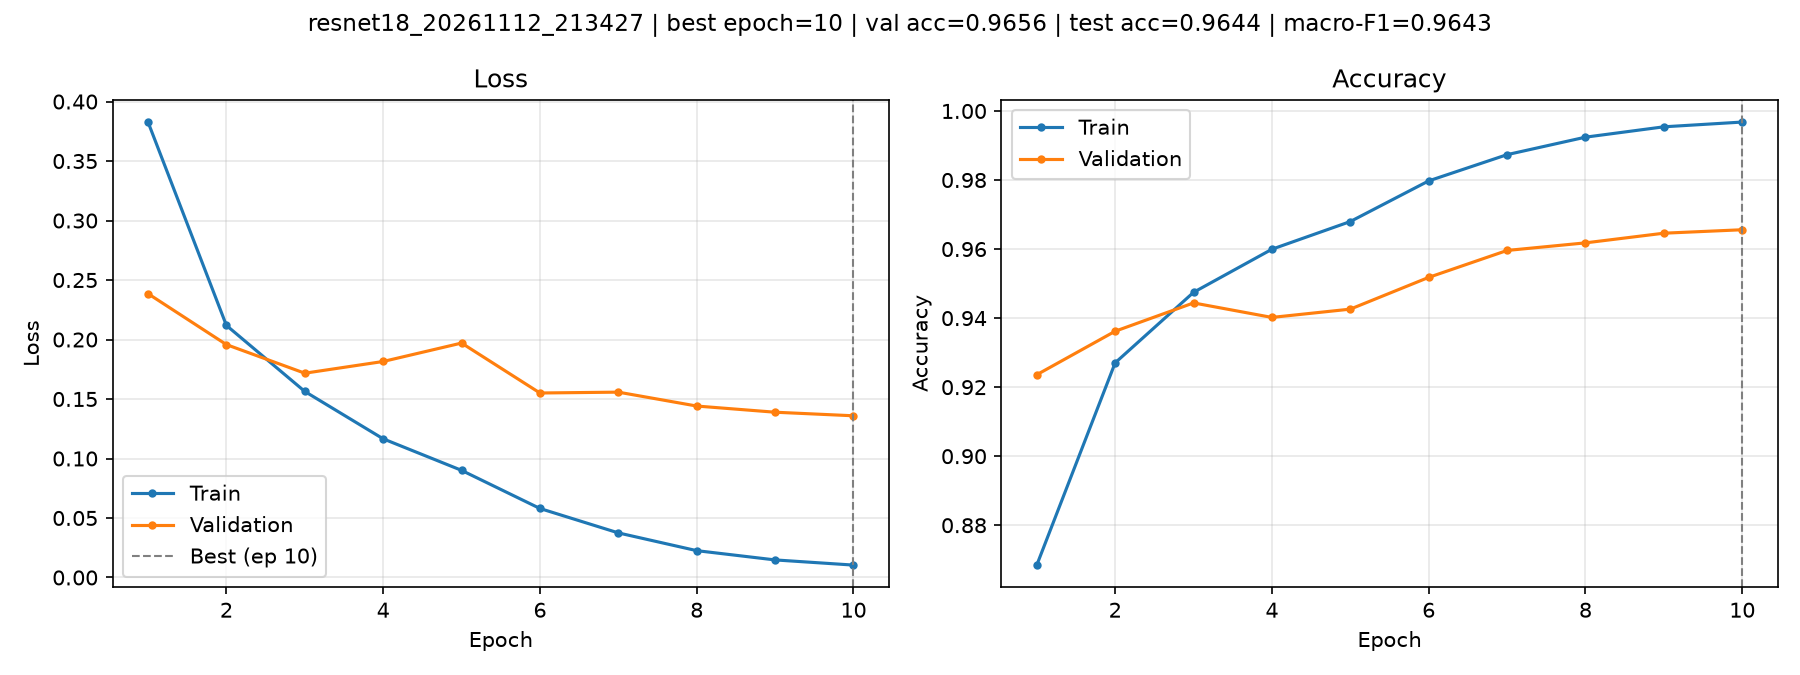


confusion_matrix_normalized.png:


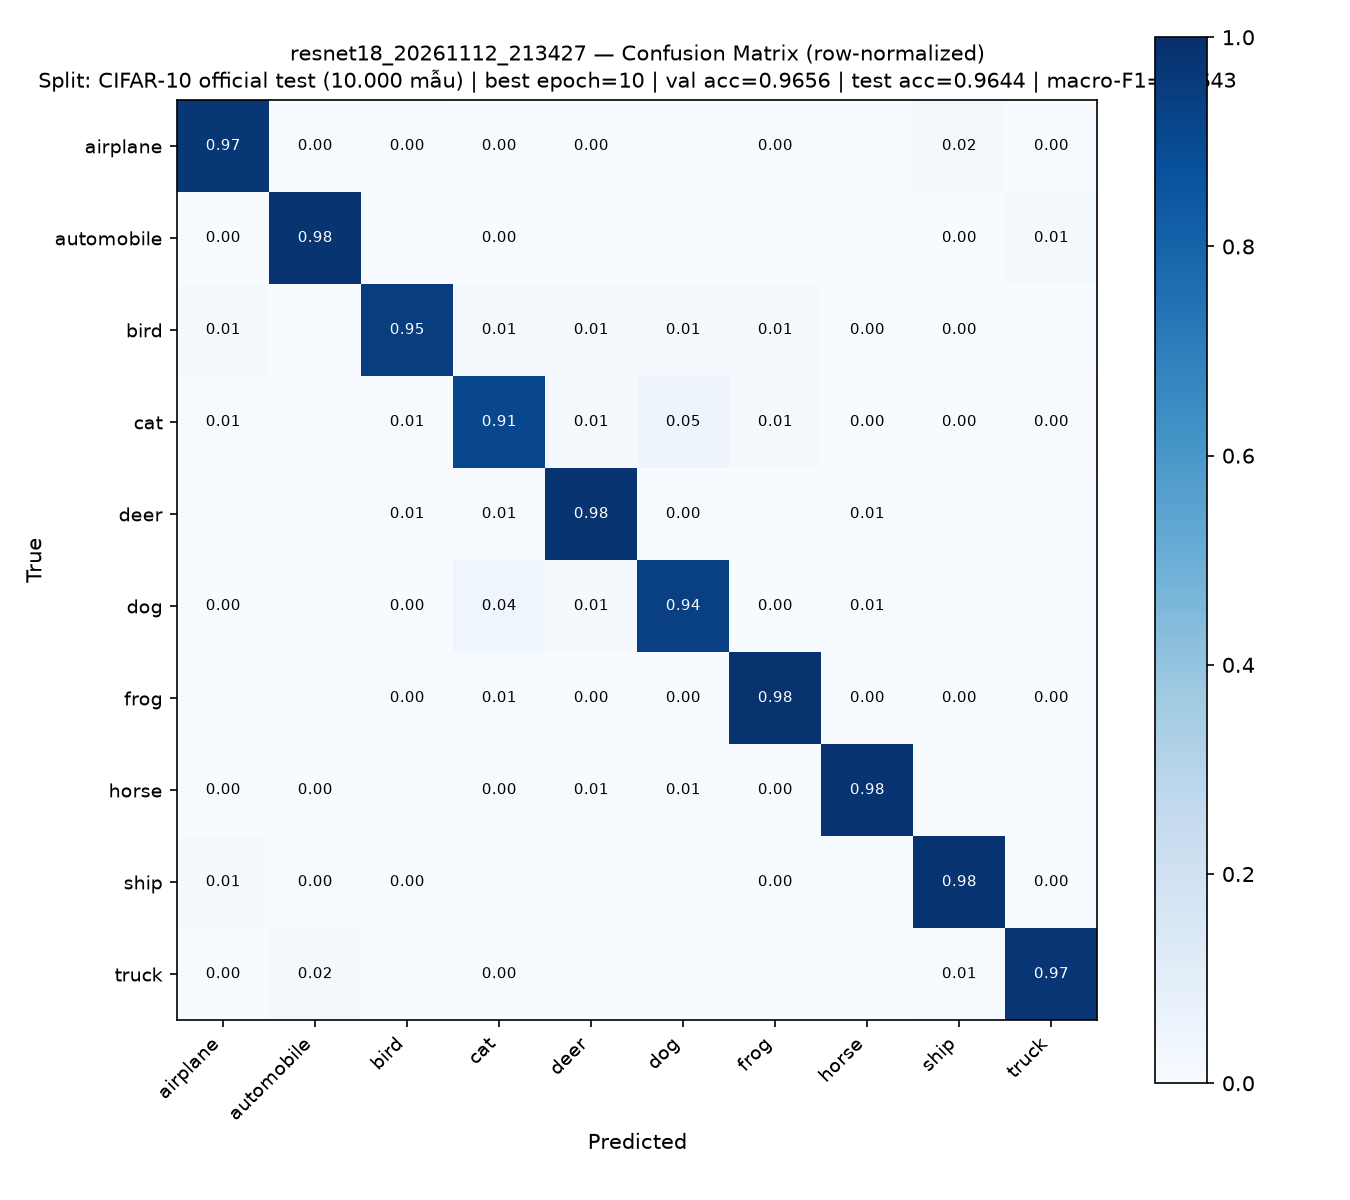


misclassified.png:


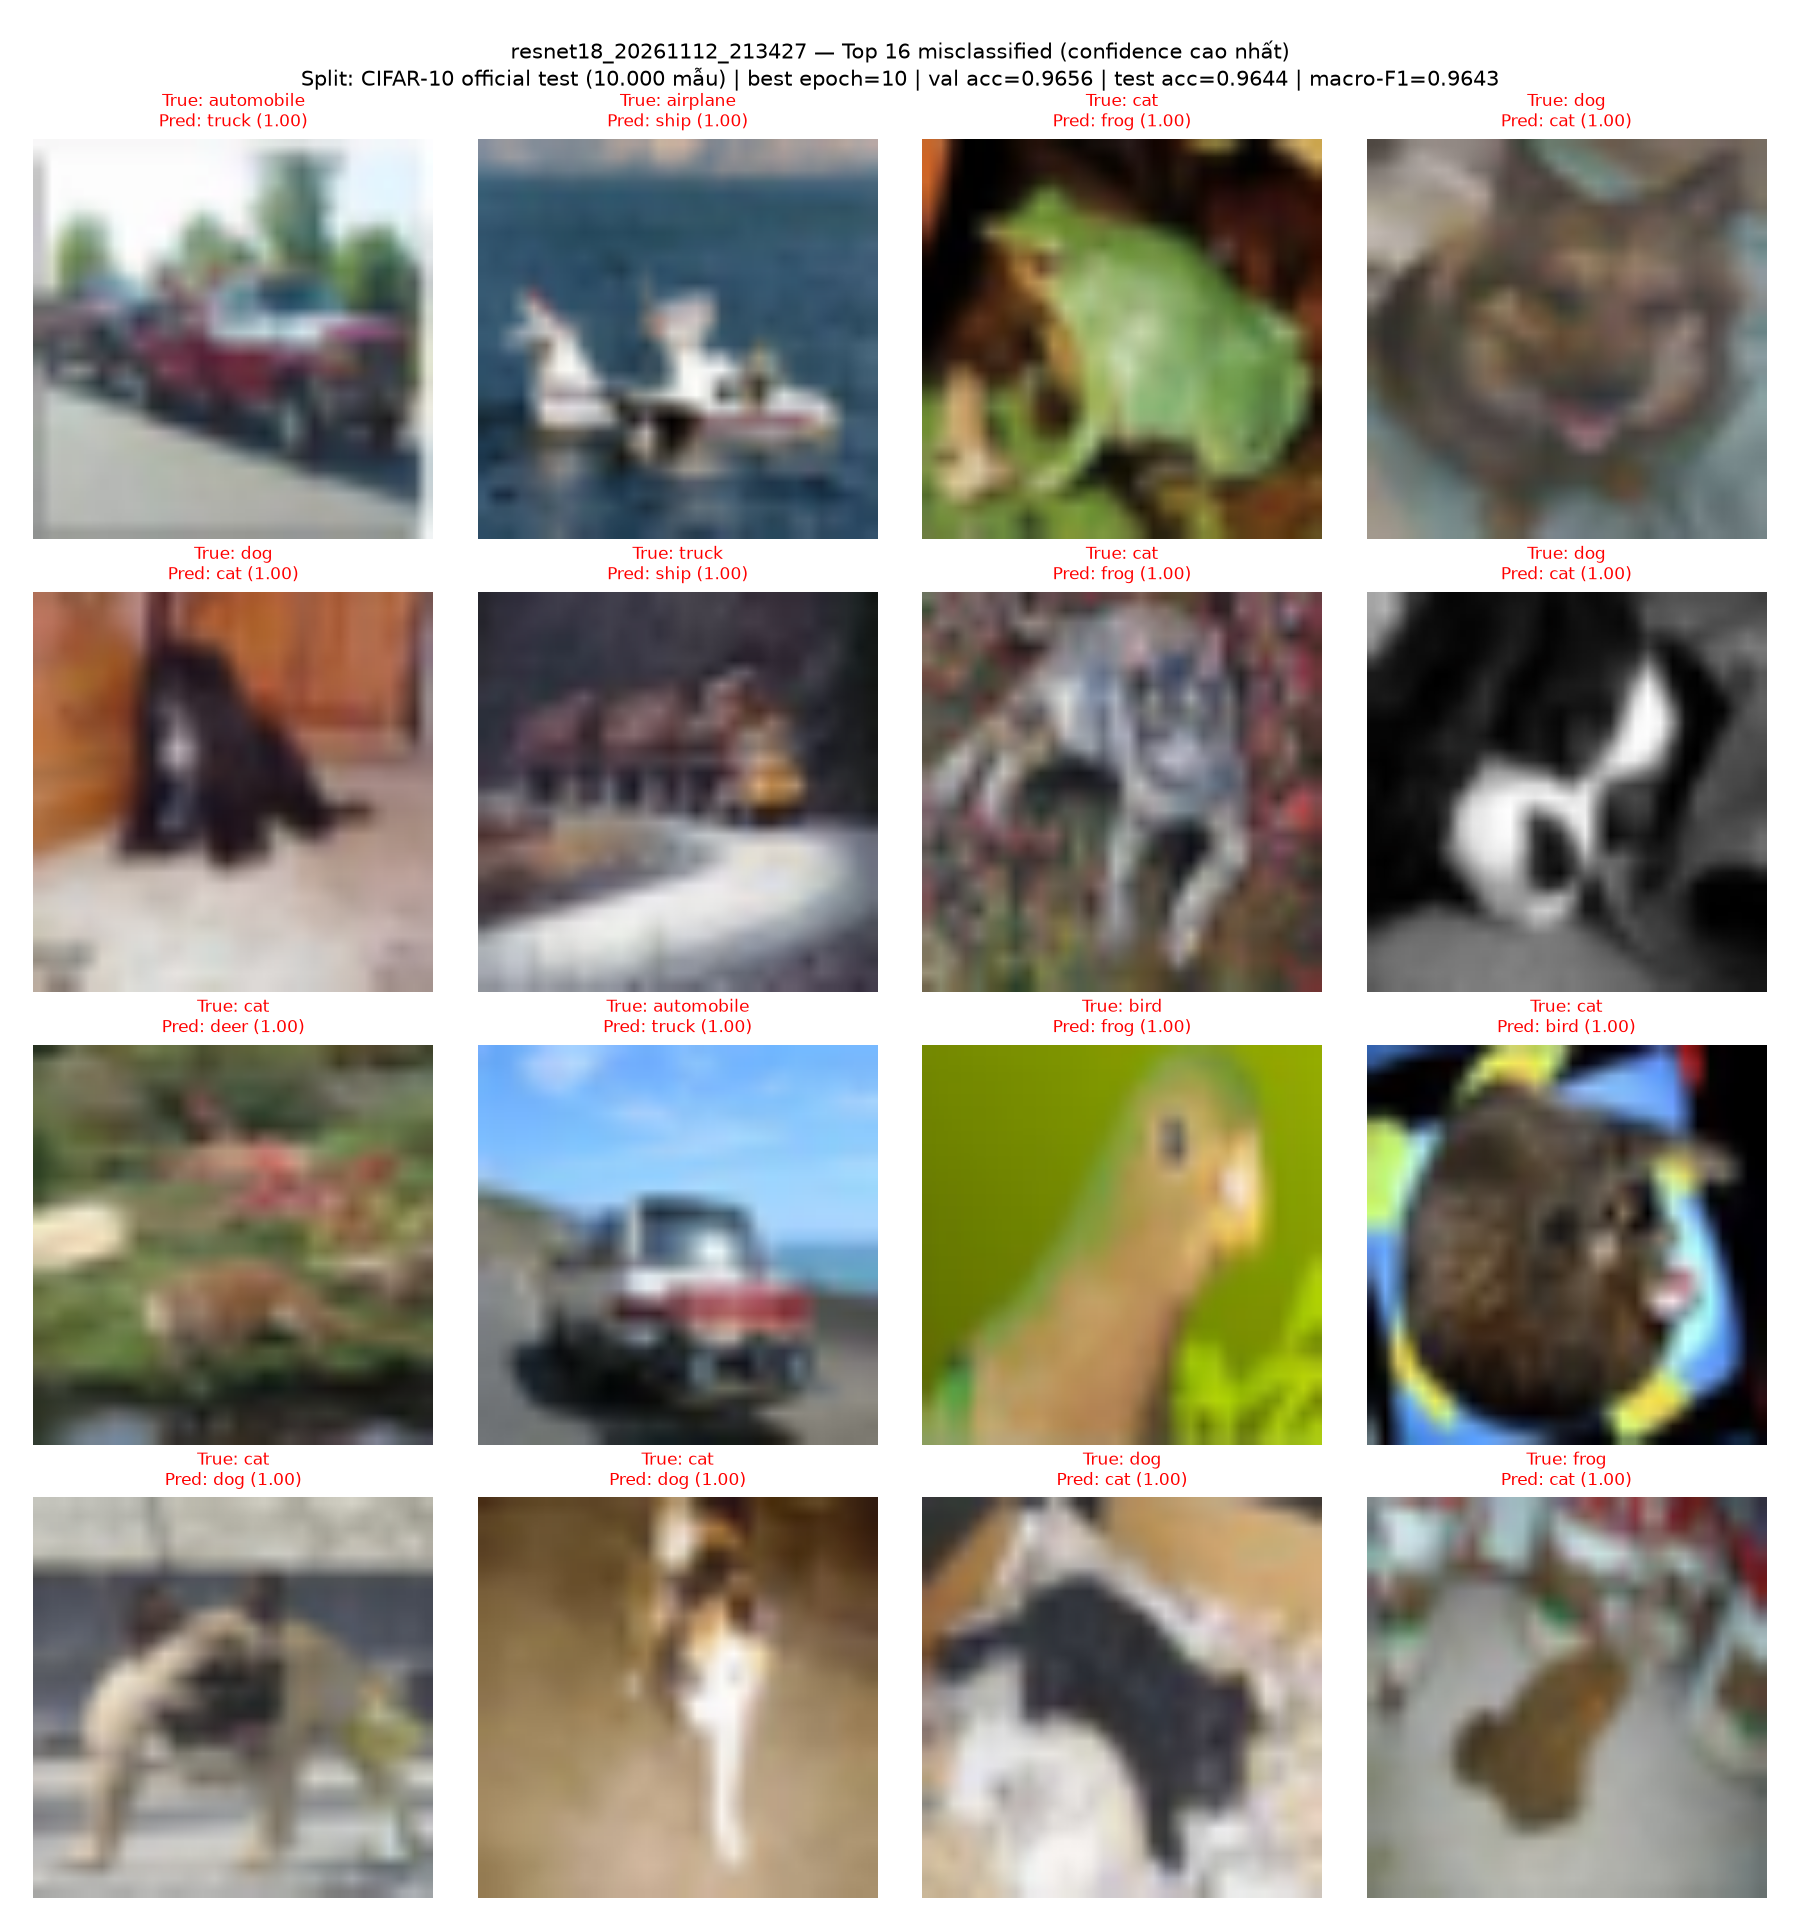


per_class_f1.png:


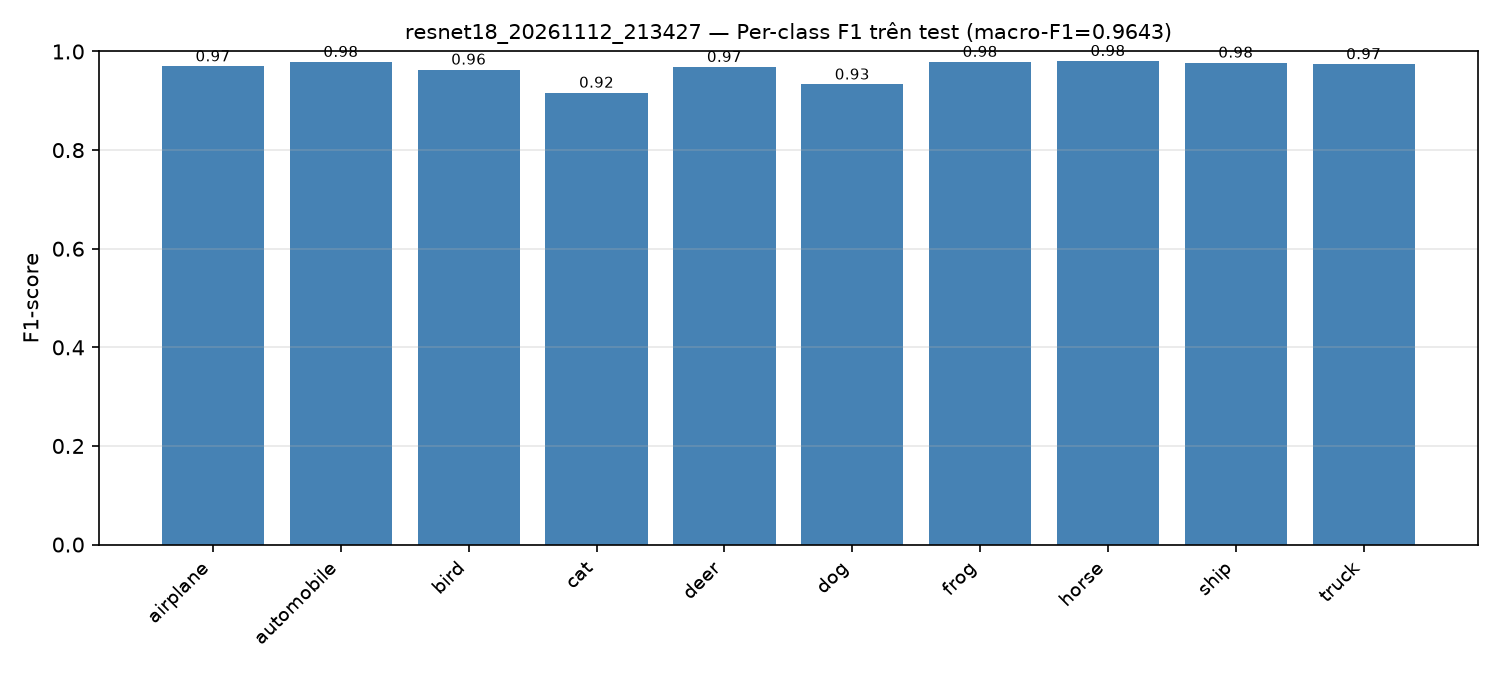


Hình của: convnext_tiny_20261112_220838

learning_curves.png:


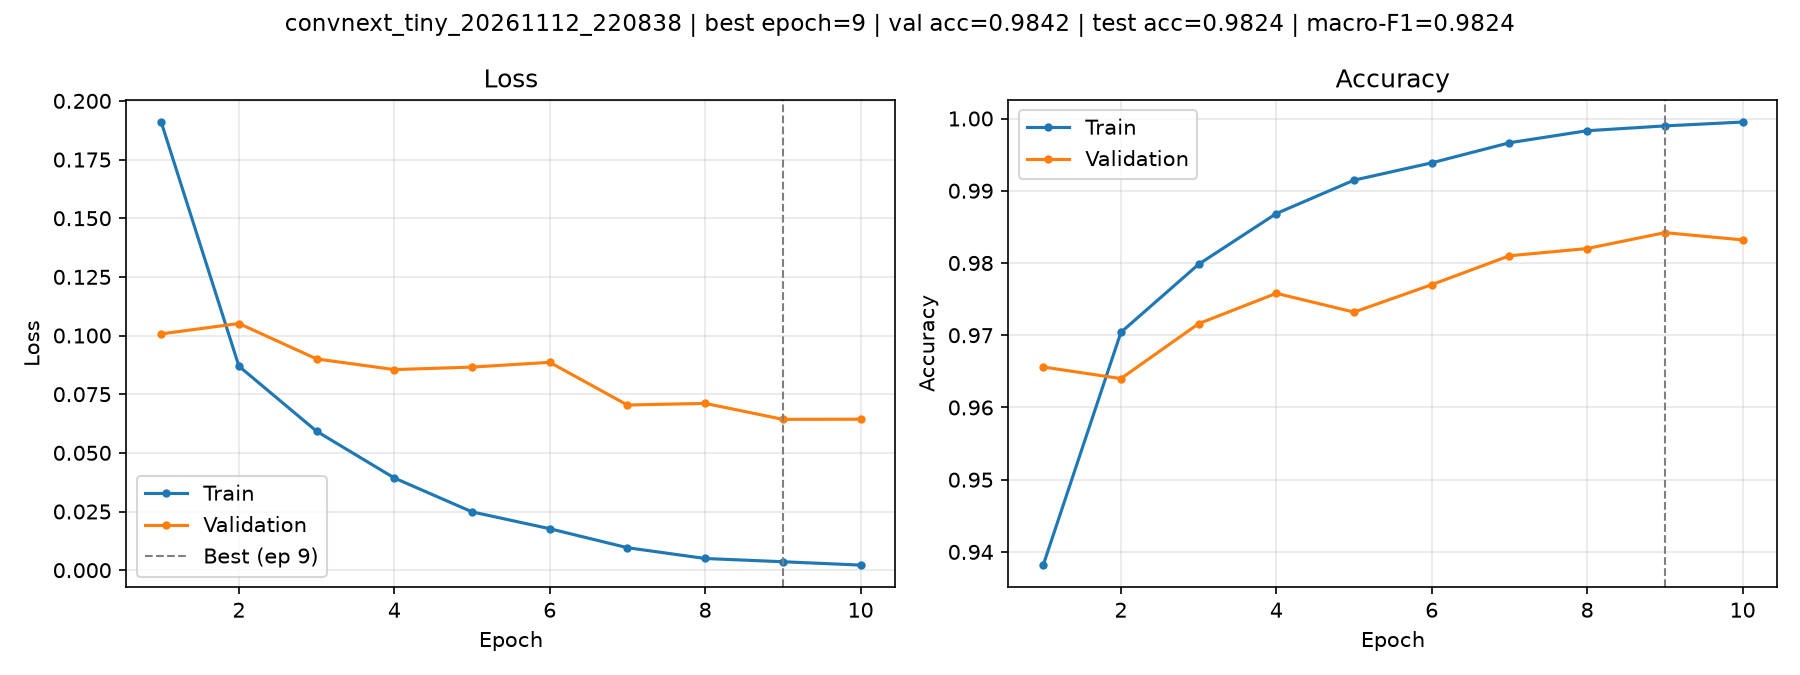


confusion_matrix_normalized.png:


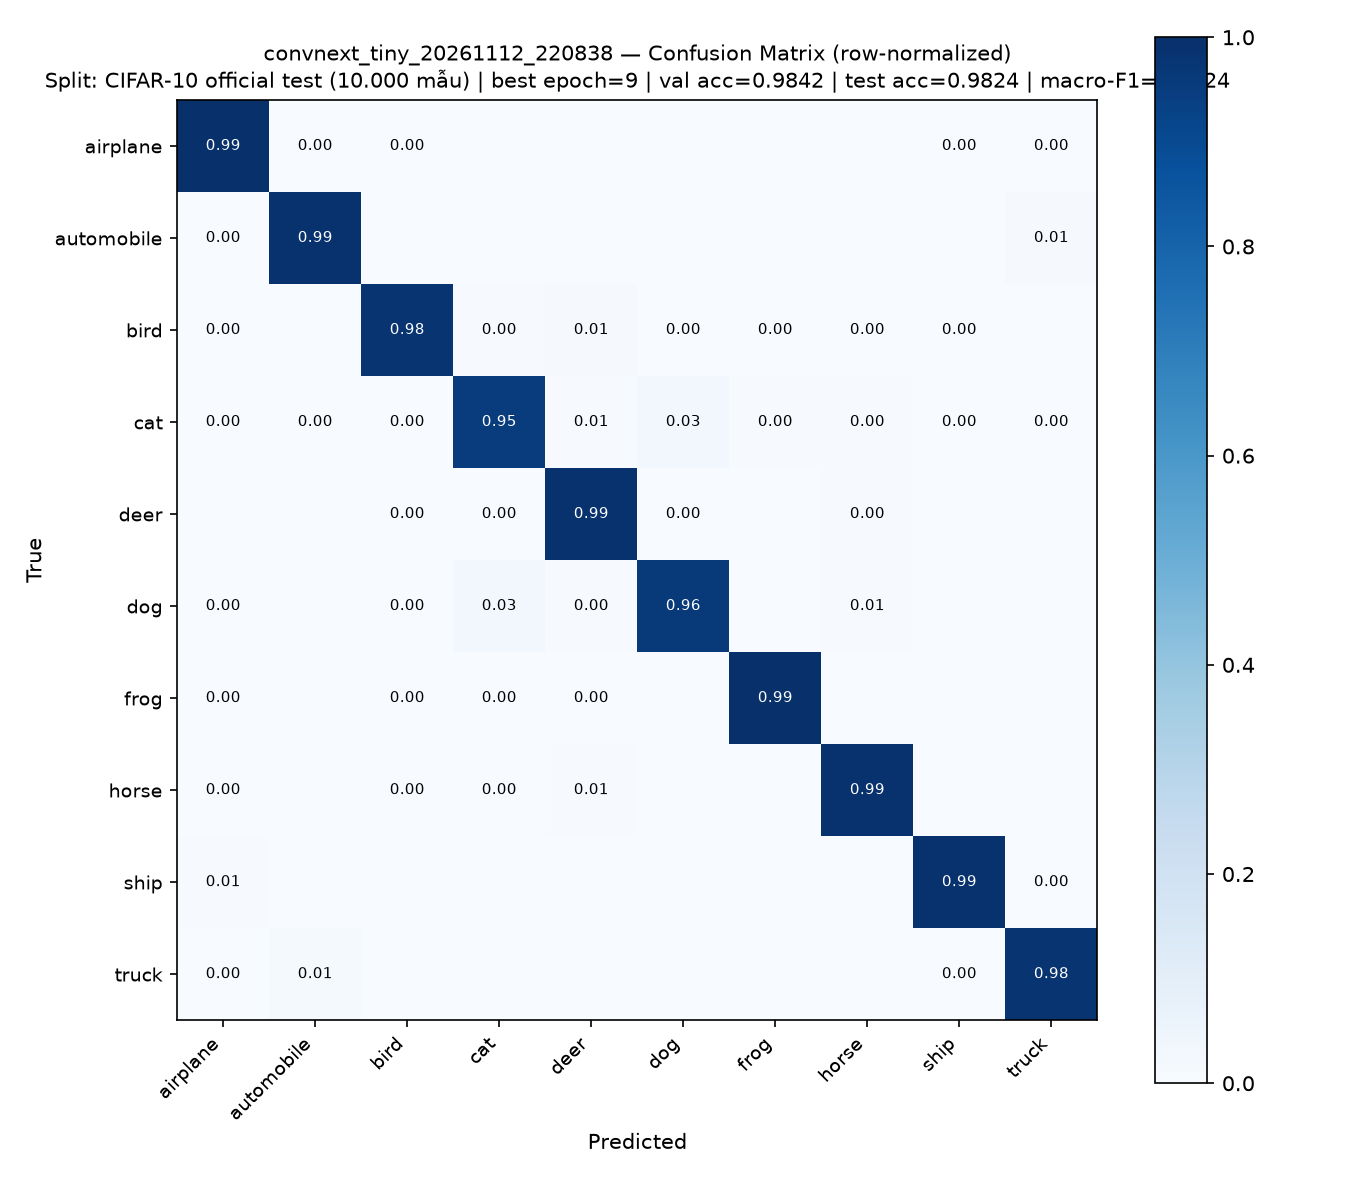


misclassified.png:


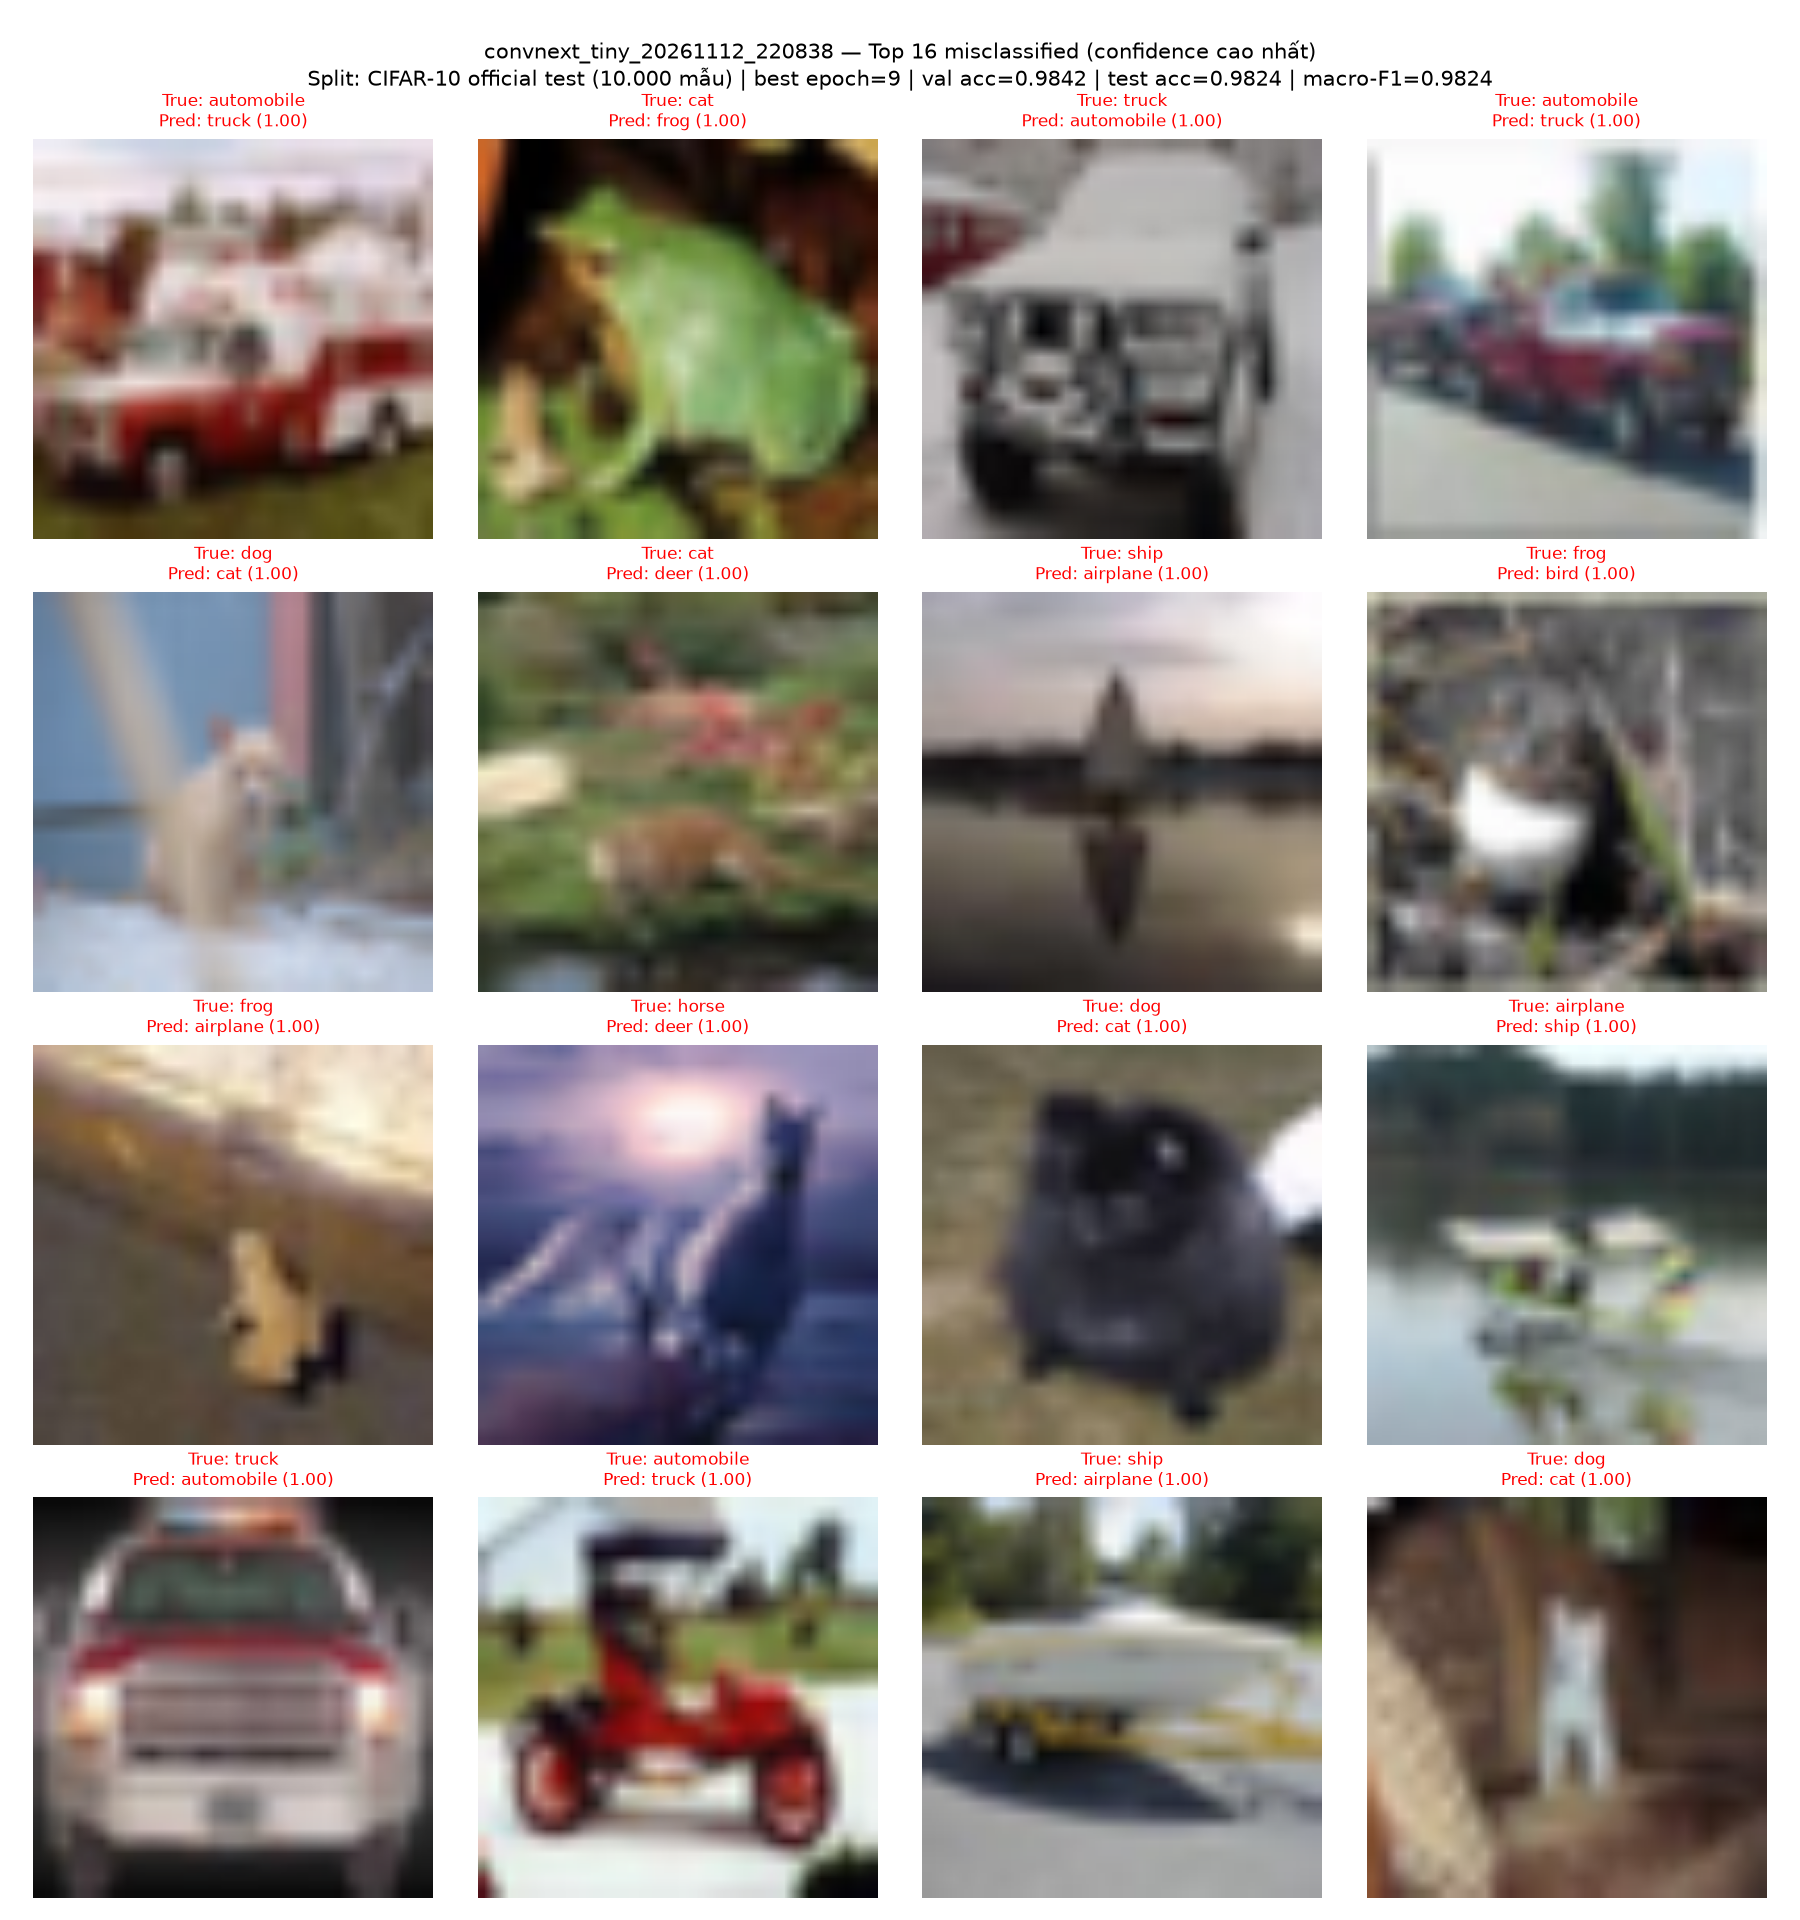


per_class_f1.png:


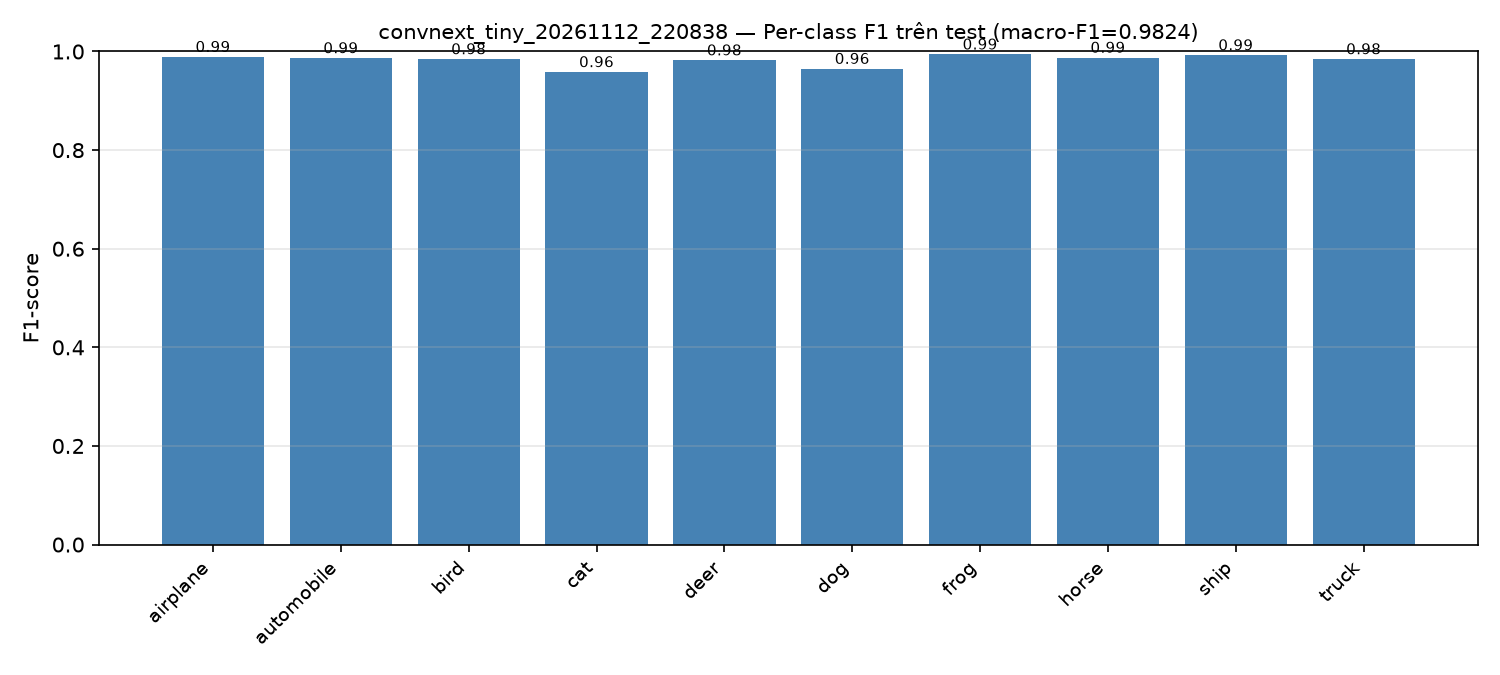

In [11]:
for model, run_name in RUNS.items():
    fig_dir = Path(config["output_dir"]) / "figures" / run_name
    print(f"\n{'='*70}")
    print(f"Hình của: {run_name}")
    print(f"{'='*70}")
    for img_name in ["learning_curves.png",
                     "confusion_matrix_normalized.png",
                     "misclassified.png",
                     "per_class_f1.png"]:
        img_path = fig_dir / img_name
        if img_path.exists():
            print(f"\n{img_name}:")
            display(Image(filename=str(img_path)))
        else:
            print(f"(không tìm thấy {img_name})")

7. Nhận xét tự động

In ra một số quan sát nhanh: model nào accuracy cao nhất, macro-F1 cao nhất,
latency thấp nhất, ít tham số nhất. Đây chỉ là tóm tắt cơ học — phần phân tích
định tính (trade-off accuracy vs compute) nên được viết trong báo cáo dựa trên bảng tổng hợp.

In [12]:
def quick_insight(test_metrics, profile_results):
    best_acc = max(test_metrics.items(), key=lambda x: x[1]["accuracy"])
    best_f1 = max(test_metrics.items(), key=lambda x: x[1]["macro_f1"])
    fastest = min(profile_results.items(),
                  key=lambda x: x[1]["latency"]["mean_ms"])
    lightest = min(profile_results.items(),
                   key=lambda x: x[1]["params_m"] or float("inf"))

    print("NHẬN XÉT NHANH")
    print(f"- Accuracy cao nhất: {best_acc[0]} ({best_acc[1]['accuracy']:.4f})")
    print(f"- Macro-F1 cao nhất: {best_f1[0]} ({best_f1[1]['macro_f1']:.4f})")
    print(f"- Latency thấp nhất: {fastest[0]} "
          f"({fastest[1]['latency']['mean_ms']:.2f} ms)")
    print(f"- Ít tham số nhất: {lightest[0]} ({lightest[1]['params_m']} M)")

quick_insight(test_metrics, profile_results)

NHẬN XÉT NHANH
- Accuracy cao nhất: convnext_tiny (0.9824)
- Macro-F1 cao nhất: convnext_tiny (0.9824)
- Latency thấp nhất: resnet18 (19.77 ms)
- Ít tham số nhất: resnet18 (11.7 M)
